# A simple Rietveld refinement

We refine the fluorapatite structure against the pattern notebook 01 fitted with Le Bail.
This time the peak intensities come from the atoms, so the fit can move them.
Along the way we read the plan's stages, the parameter table and the bond lengths, draw the refined structure, and save the work as a project.

*Written by Claude Code, Anthropic's coding agent, for the rietx project.*

**You need** rietx 1.10 or later, which the next cell installs.
Notebook 01 introduces the pattern and how to read a fit's summary.

**The data** is `FAP.XRA` from the GSAS-II `LabData` tutorial, with a CIF transcribed from the same tutorial's experiment file.
Both ship with rietx.
Fluorapatite, Ca₅(PO₄)₃F, has seven atomic sites in space group P6₃/m.

**Runtime** is under 30 seconds on a laptop.

In [ ]:
%pip install rietx

## A first refinement

This is the example on the rietx home page.
The [`mccusker_structural`](https://rietx.org/docs/stable/reference/plans.html#mccusker-structural) plan refines the profile first and the atoms after it.

In [1]:
import tempfile
from pathlib import Path

import rietx as rx
from rietx.examples import examples_dir

data = rx.read_pattern(examples_dir() / "FAP.XRA")  # GSAS raw format
structure = rx.Structure.from_cif(examples_dir() / "fluorapatite.cif")
instrument = rx.Instrument.bragg_brentano(radiation="CuKa")
instrument.geometry.axial_sl.value = 0.02  # axial divergence
instrument.geometry.axial_hl.value = 0.02
instrument.background = rx.BackgroundChebyshev.with_terms(6)

ref = rx.Refinement(structure, instrument)
result = ref.fit(data, plan="mccusker_structural", two_theta_limits=(15, 130))
print(result)

RefinementResult: converged (rietveld)
  stage scale_bkg: converged (2 evals, ftol=1e-06)
  stage zero: converged (42 evals, ftol=1e-06)
  stage cell: converged (36 evals, ftol=1e-06)
  stage profile_w: converged (13 evals, ftol=1e-06)
  stage profile: converged (10 evals, ftol=1e-06)
  stage extra_components: converged (7 evals, ftol=1e-06)
  stage coordinates: converged (6 evals, ftol=1e-06)
  stage biso: converged (6 evals, ftol=1e-06)
  stage preferred_orientation: converged (4 evals, ftol=1e-06)
  stage extinction: converged (2 evals, ftol=1e-06)
  stage roughness: converged (2 evals, ftol=1e-06)
  stage closing: converged (9 evals, ftol=solver default), max|Δθ|/esd=0.000
  diagnostics: 3 rows, 0 errors; no deliverable given, so none is printed in full
    FLOOR_HIT at phases.0.extinction: warning under qpa, structure, magnetic
    RESOLUTION_UNCONSTRAINED at instrument.profile.u, .v, .w: warning under microstructure, calibration
    PATTERN_UNDERSAMPLED: warning under qpa, struct

Three warnings came back, one line each.
A warning matters for some uses of a fit and not others, so each line ends with the [purposes](https://rietx.org/docs/stable/reference/result.html#printing-a-result) it is a warning under.
`structure` is the atoms, `qpa` the phase fractions, `microstructure` the crystallite size and strain, `calibration` an instrument calibrated on a standard, and `magnetic` a magnetic structure's moments.

- [`FLOOR_HIT`](https://rietx.org/docs/stable/reference/diagnostics-refinement.html#floor-hit): the extinction coefficient ended on its floor of 0, so this specimen shows no extinction to measure.
- [`RESOLUTION_UNCONSTRAINED`](https://rietx.org/docs/stable/reference/diagnostics-refinement.html#resolution-unconstrained): the peaks are mostly Lorentzian, so do not quote the Gaussian widths U, V and W.
- [`PATTERN_UNDERSAMPLED`](https://rietx.org/docs/stable/reference/diagnostics-refinement.html#pattern-undersampled): the step count notebook 01 measured.

None of them invalidates the structure, but each one limits what you can quote.
Two are warnings under `structure`, and the third concerns only the peak widths.

`print(result)` is not told what the fit is for, so it prints none of them in full.
The line after the three says how to read them: pass your purpose to `ref.summary` as `deliverable=`, or look in [`result.diagnostics`](https://rietx.org/docs/stable/reference/result.html#diagnostics), which holds every warning with its message.
Notebook 02b ends by printing the summary for a structure.
[Diagnostic codes](https://rietx.org/docs/stable/reference/diagnostics.html) lists every code.

Look at the fit before reading any number.

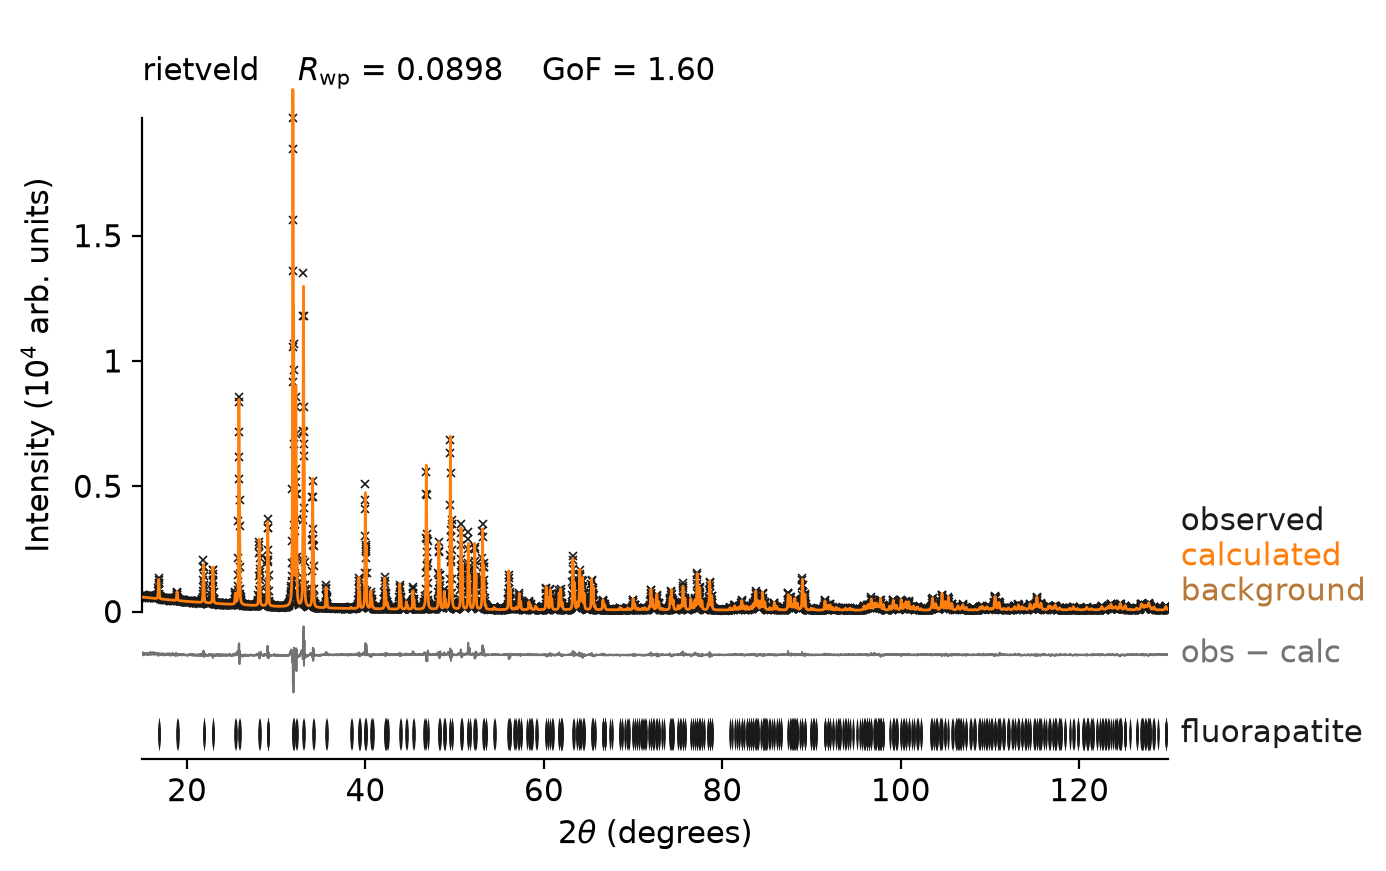

In [2]:
result.plot()

A good fit leaves the [difference curve](https://rietx.org/docs/stable/reference/figures.html#the-fit-figure) as flat noise, with no peak-shaped wiggle at any tick.
Here the largest misfit sits on the strongest peaks, near 32°.

## The plan's stages

The stage lines in the summary above are the plan's stages, in the order they ran.
Each stage frees one group of parameters and keeps every group freed before it.
The last line, [`closing`](https://rietx.org/docs/stable/reference/refinement.html#the-closing-stage), is the stage every plan ends with: it refines everything once more, with peak windows that keep more of each peak's tails.
[Plan presets](https://rietx.org/docs/stable/reference/plans.html) draws the stages of every plan.

[`result.stages`](https://rietx.org/docs/stable/reference/refinement.html#stage-results) holds one record per stage.
Ask the seventh, `coordinates`, which parameters it freed.

In [3]:
result.stages[6].freed

['phases.0.atoms.0.dof.0',
 'phases.0.atoms.1.dof.0',
 'phases.0.atoms.1.dof.1',
 'phases.0.atoms.2.dof.0',
 'phases.0.atoms.2.dof.1',
 'phases.0.atoms.4.dof.0',
 'phases.0.atoms.4.dof.1',
 'phases.0.atoms.5.dof.0',
 'phases.0.atoms.5.dof.1',
 'phases.0.atoms.6.dof.0',
 'phases.0.atoms.6.dof.1',
 'phases.0.atoms.6.dof.2']

The coordinates stage freed no x, y or z.
Every parameter it freed has `dof` in its name.

## The parameter table

[`ref.parameters()`](https://rietx.org/docs/stable/reference/parameter-table.html#rows) lists every parameter the model has, whether it varies or not.
Pick out the rows for one oxygen site, O7, which sits on a general position.

In [4]:
[row for row in ref.parameters() if row.path.startswith("phases.0.atoms.6.")]

[phases.0.atoms.6.x  0.33985(63)  tied = 0.339848 + 1·phases.0.atoms.6.dof.0,
 phases.0.atoms.6.y  0.25770(63)  tied = 0.257698 + 1·phases.0.atoms.6.dof.1,
 phases.0.atoms.6.z  0.07058(62)  tied = 0.0705796 + 1·phases.0.atoms.6.dof.2,
 phases.0.atoms.6.dof.0  0.00000(63)  vary,
 phases.0.atoms.6.dof.1  0.00000(63)  vary,
 phases.0.atoms.6.dof.2  0.00000(62)  vary,
 phases.0.atoms.6.occ  1  fixed,
 phases.0.atoms.6.biso  0.36(11)  vary]

Each row gives the path, the value with its esd, and what the parameter is doing.

The atom's x, y and z are not refined directly.
Each is tied to one `dof`, a step along a direction the site symmetry allows.
O7 is on a general position, so it has three.
An atom on a mirror plane has two, and one on a three-fold axis has one.
The coordinates follow from the `dof` values, so the symmetry always holds.
[Site-symmetry degrees of freedom](https://rietx.org/docs/stable/theory/parameterisation.html#site-symmetry-degrees-of-freedom) derives them.

## Is the structure chemically sensible?

A fit can match the pattern with atoms in impossible places.
[`result.geometry`](https://rietx.org/docs/stable/reference/derived.html#bonding-geometry) lists the bonds the refined structure implies, with esds.
A phosphate's P–O bonds are close to 1.54 Å.

In [5]:
[
    bond
    for bond in result.geometry.bonds
    if bond.atom_1 == "P3" and bond.atom_2.startswith("O")
]

[P3–O7  1.5253(47) Å  10_555,
 P3–O7  1.5253(47) Å,
 P3–O5  1.5527(68) Å,
 P3–O6  1.5752(64) Å]

Each row is one bond from P3.
A symmetry code after the distance names the image of the oxygen that the bond reaches.
O7 sits on both sides of the mirror plane, so it appears twice.
All four bonds are within 0.04 Å of 1.54 Å.
Some differ from it by several esds.
An esd counts only the noise in the data and no error in the model, so a real structure can sit further from a reference than its esd suggests.

## The refined structure

[`rx.viz.render_structure`](https://rietx.org/docs/stable/reference/figures.html#structure-pictures) draws a structure the way the GUI's 3D viewer does, from the refined values the model holds now.
[`view`](https://rietx.org/docs/stable/reference/figures.html#views) says where it is seen from: an axis (`"a"`, `"b"`, `"c"`), a direction `[u, v, w]`, the normal to a plane `{"hkl": (h, k, l)}`, or `"auto"`.
Looking down c shows what makes this an apatite: fluorine channels at the cell corners, each ringed by Ca2, with the PO₄ tetrahedra and the Ca1 columns between them.

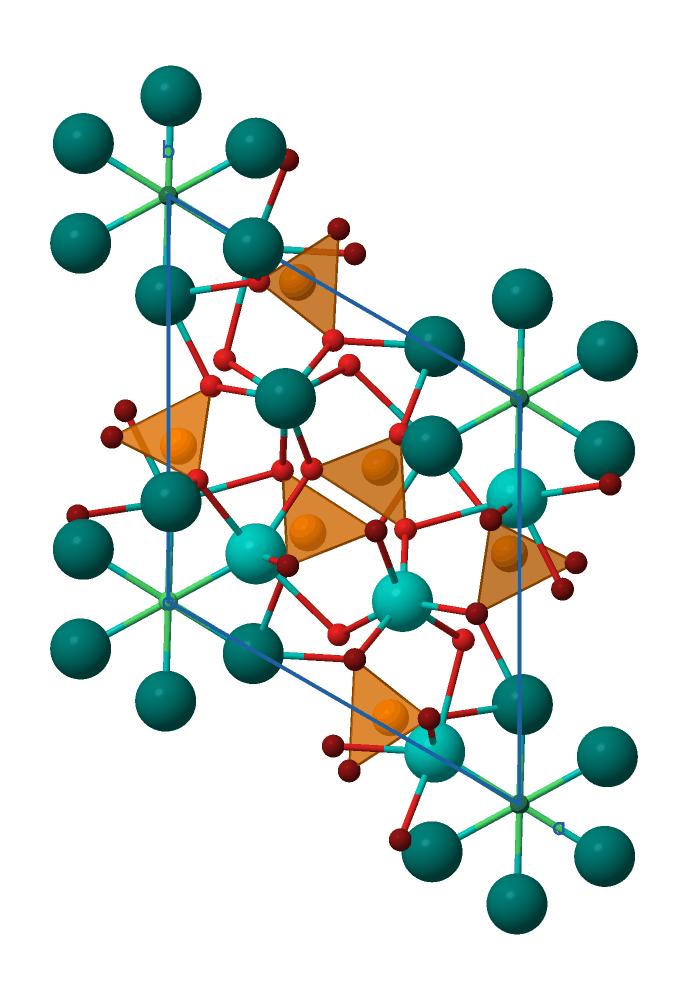

In [6]:
rx.viz.render_structure(ref.structure, view="c")

Atoms outside the cell, drawn to complete a polyhedron or a bond, are shaded darker, so one element shows in two shades.
The orange tetrahedra are the phosphate groups.

Down an axis the picture is flat.
`turn` adds small rotations after the view, in degrees about the screen's x and y axes.
Here the default view is tipped 15° about the screen's x axis, so the cell reads as a box and the tetrahedra show their stacking along c.

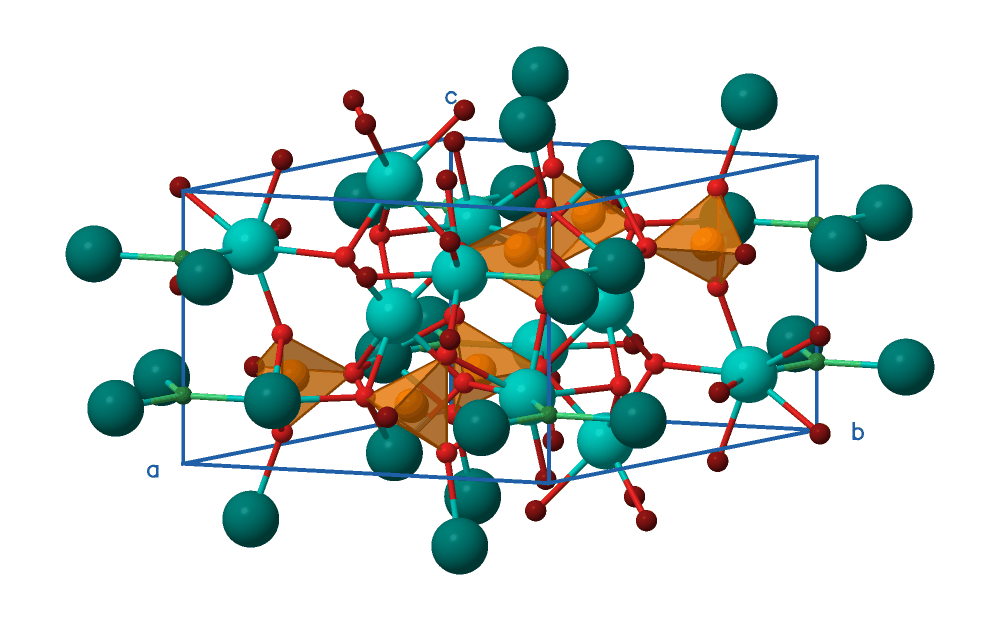

In [7]:
rx.viz.render_structure(ref.structure, turn="-15x")

Each call takes a fraction of a second, so try other views.
[`mode="ellipsoid"`](https://rietx.org/docs/stable/reference/figures.html#drawing-options) draws the displacement parameters, `atom_labels=True` names each site, and `path="apatite.png"` writes the picture to a file.

## Saving the work as a project

Everything so far lives in this Python session and goes when it ends.
A [project](https://rietx.org/docs/stable/concepts/project.html) keeps a refinement on disk as a directory whose name ends `.rex`.
The GUI opens the same directory ([`rietx gui`](https://rietx.org/docs/stable/reference/cli.html#rietx-gui) `fluorapatite.rex`), so a project started in code can be continued by hand, and the reverse.

[`Project.create`](https://rietx.org/docs/stable/reference/project.html#creating-a-project) takes the pattern file, the models and the protocol, and starts a history of its own.
`project.fit()` refines and records each stage there, and `project.save()` writes the settings.

In [8]:
project = rx.Project.create(
    Path(tempfile.mkdtemp()) / "fluorapatite.rex",
    pattern=examples_dir() / "FAP.XRA",
    structure=ref.structure,
    instrument=ref.instrument,
    plan="mccusker_structural",
    two_theta_limits=(15, 130),
)
project.fit()
project.save()
project

Project('fluorapatite.rex', 'FAP.XRA', 13 history nodes, at n0012)

The project's [history](https://rietx.org/docs/stable/concepts/fit.html#the-history) holds a root node and one node per stage of the fit.
List the directory to see what it wrote.

In [9]:
sorted(item.name for item in project.path.iterdir())

['FAP.XRA', 'exports', 'history.jsonl', 'live', 'project.json']

Each entry holds [one kind of fact](https://rietx.org/docs/stable/concepts/project.html#what-each-file-is-for), and no fact is stored twice.

- `FAP.XRA` is the pattern, copied byte for byte. `project.json` records its checksum, which reader opened it, and a fingerprint of the numbers that reader produced. A changed file and a changed reader can then be told apart.
- `project.json` holds the settings: the plan, the fitted range, excluded regions, and the GUI's own choices. It holds no refined values.
- `history.jsonl` holds every node of the history, one JSON line each, appended as each stage finishes. The node at its head is the working state, so the refined values live here.
- `live/` holds each run's record while it happens, which [`rietx watch`](https://rietx.org/docs/stable/reference/cli.html#rietx-watch) and the GUI draw from.
- `exports/` is where exported files go, such as a CIF of the refined structure.

[`rx.Project.open`](https://rietx.org/docs/stable/reference/project.html#opening-a-project) reopens a project in code.
Every verb writes into the directory, so to look at someone's project without changing it, [open a copy](https://rietx.org/docs/stable/concepts/project.html#opening-a-project-changes-it) (`rietx gui --scratch` makes one).

Notebook 02b starts from this fit and steers it: a constraint between three atoms, two parameters the data cannot separate, and a parameter held through a plan.